In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/titanic.csv")
print("Dimensions :", df.shape)
df.info()
df.head()

Dimensions : (891, 8)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 60.9 KB


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [2]:
manquantes = df.isnull().sum()
print(manquantes[manquantes > 0])
print((df.isnull().mean() * 100).round(1))

Age         177
Embarked      2
dtype: int64
Survived     0.0
Pclass       0.0
Sex          0.0
Age         19.9
SibSp        0.0
Parch        0.0
Fare         0.0
Embarked     0.2
dtype: float64


In [3]:
print("Survie globale :", round(df["Survived"].mean() * 100, 1), "%")
for col in ["Sex", "Pclass", "Embarked"]:
    print("\nSurvie par", col)
    print((df.groupby(col)["Survived"].mean() * 100).round(1))

Survie globale : 38.4 %

Survie par Sex
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Survie par Pclass
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

Survie par Embarked
Embarked
C    55.4
Q    39.0
S    33.7
Name: Survived, dtype: float64


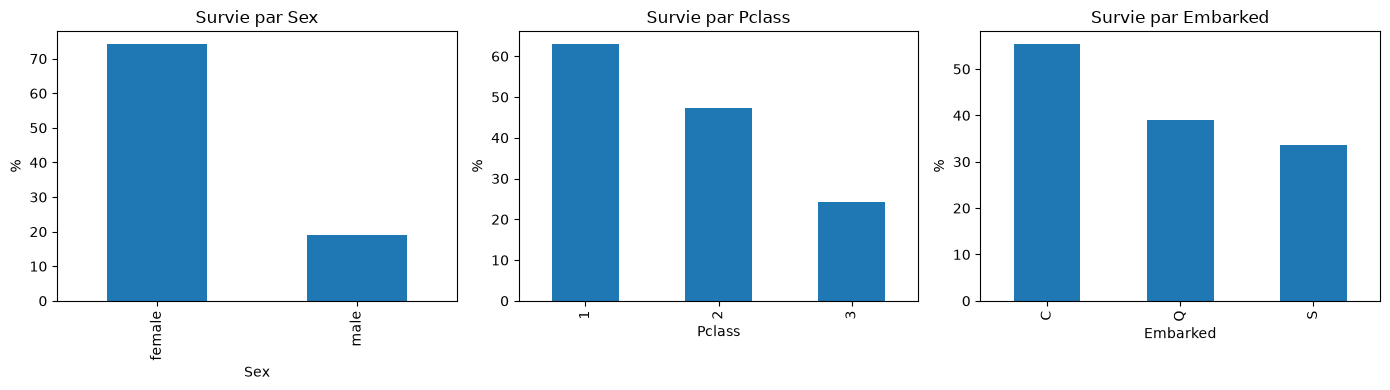

In [4]:
ig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    (df.groupby(col)["Survived"].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_title("Survie par " + col)
    ax.set_ylabel("%")
plt.tight_layout()
plt.show()

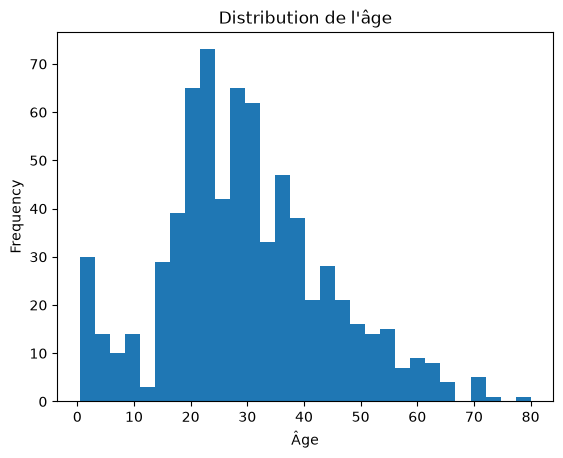

In [5]:
df["Age"].plot(kind="hist", bins=30, title="Distribution de l'âge")
plt.xlabel("Âge")
plt.show()

## Choix de préparation (réalisés dans le pipeline de `src/train.py`)
- **Âge manquant** : remplacé par la médiane (la distribution est asymétrique).
- **Port d'embarquement manquant** : remplacé par la valeur la plus fréquente.
- **Sexe et port** : transformés en colonnes 0/1 (encodage one-hot).
- **Âge, prix, classe, famille** : mis à l'échelle (StandardScaler).
- Cette préparation est faite dans le pipeline, avec les statistiques du jeu d'entraînement seulement, pour éviter toute fuite d'information vers le test.

## Conclusion
Les femmes survivent bien plus que les hommes, et les passagers de 1re classe plus que ceux de 3e classe. L'âge est manquant pour environ un cinquième des passagers, et le port d'embarquement pour très peu. Ces constats justifient les choix ci-dessus.
